In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 04 - Demography and pensions

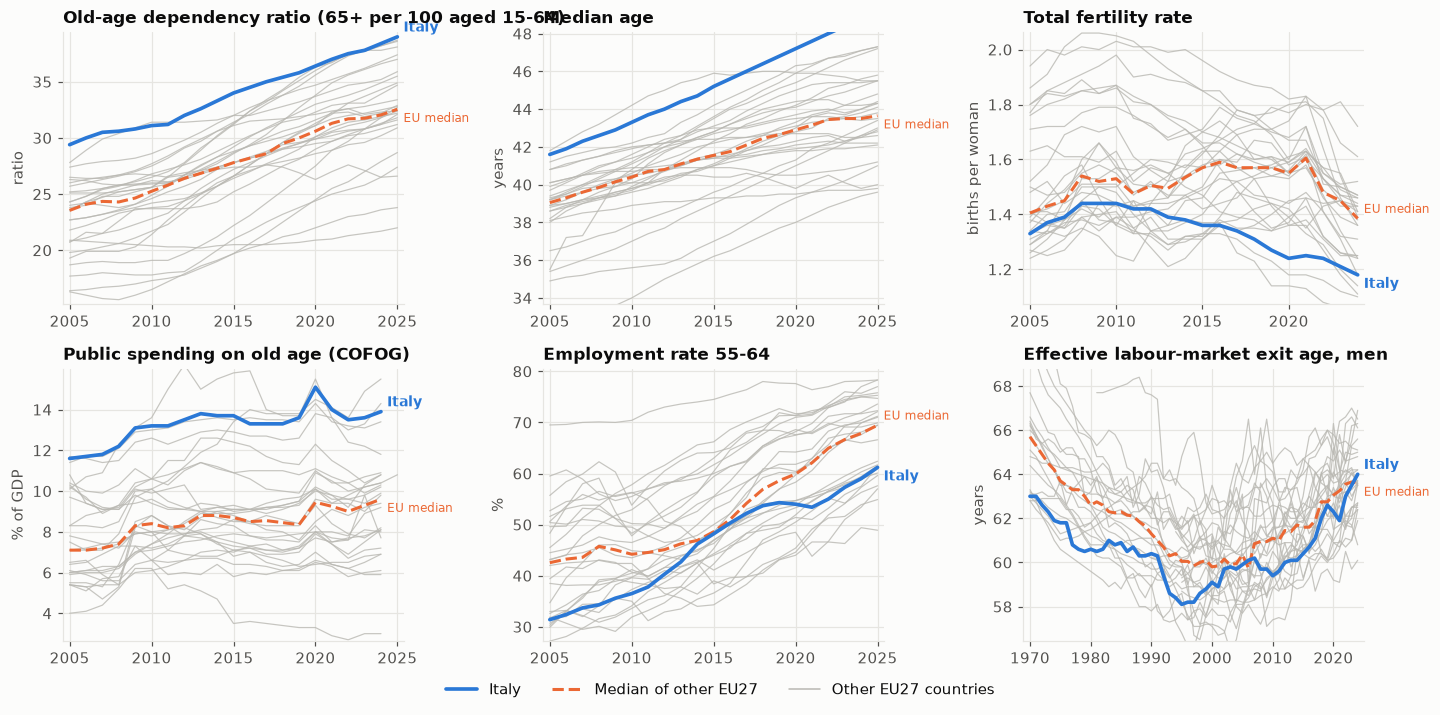

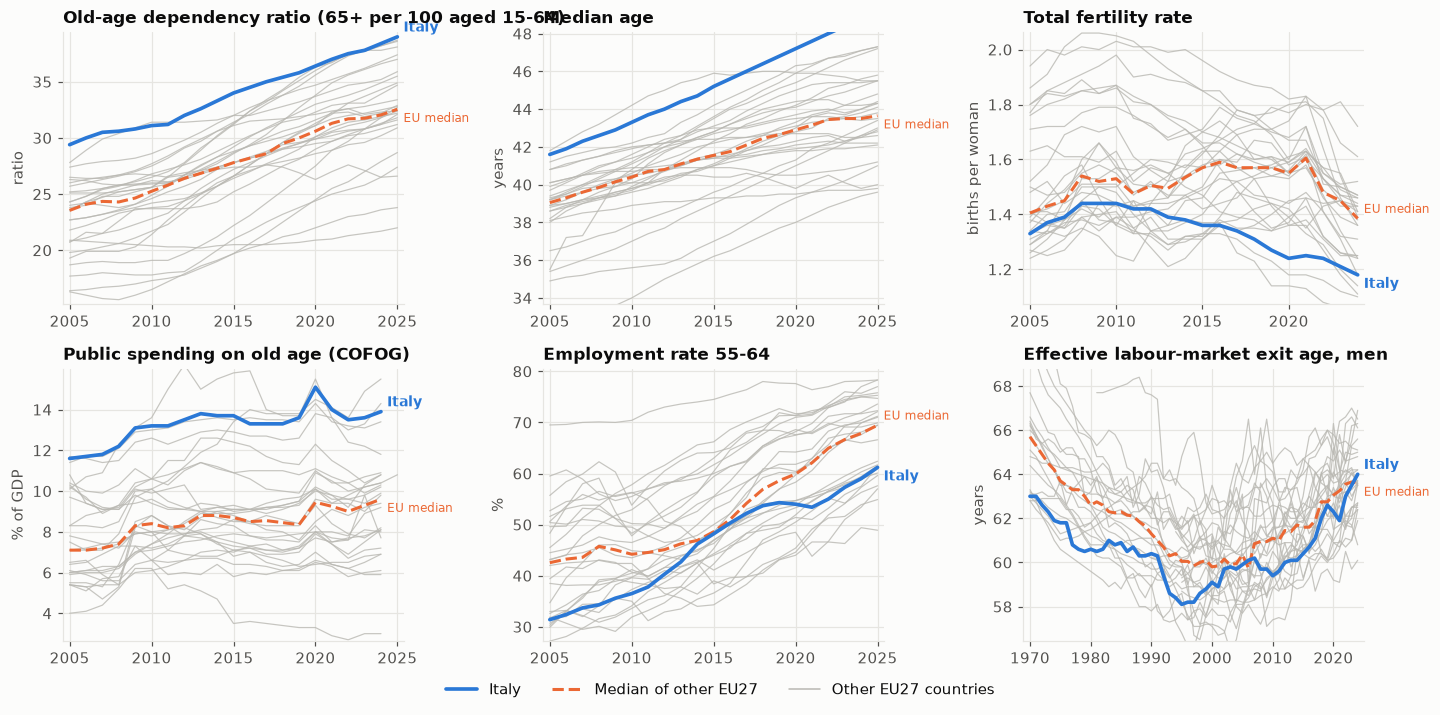

In [2]:
small_multiples(panel, [
    ("old_age_dependency", "Old-age dependency ratio (65+ per 100 aged 15-64)", "ratio"),
    ("median_age", "Median age", "years"),
    ("fertility_rate", "Total fertility rate", "births per woman"),
    ("pension_spend_pct_gdp", "Public spending on old age (COFOG)", "% of GDP"),
    ("employment_rate_55_64", "Employment rate 55-64", "%"),
    ("oecd_exit_age_male", "Effective labour-market exit age, men", "years"),
], ncols=3, name="04_demography_pensions_overview")

Italy spends 13.7% of GDP; peers' ageing-line predicts 10.8%


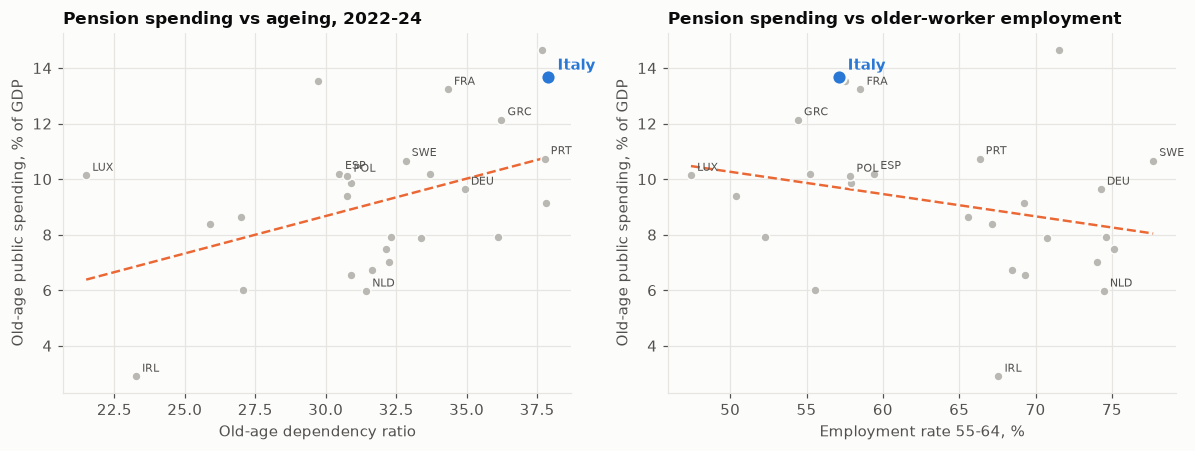

In [3]:
# Does Italy spend more on pensions than its age structure explains? (EU27, 2022-2024 average)
win = slice(2022, 2024)
x = wide(panel, "old_age_dependency", EU27_ISO3).loc[win].mean(); y = wide(panel, "pension_spend_pct_gdp", EU27_ISO3).loc[win].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
scatter_italy(axes[0], x, y, "Old-age dependency ratio", "Old-age public spending, % of GDP", "Pension spending vs ageing, 2022-24")
e = wide(panel, "employment_rate_55_64", EU27_ISO3).loc[win].mean()
scatter_italy(axes[1], e, y, "Employment rate 55-64, %", "Old-age public spending, % of GDP", "Pension spending vs older-worker employment")
fig.tight_layout(); save(fig, "04_pension_scatter")
b = np.polyfit(x.drop(ITALY).dropna(), y.drop(ITALY).dropna().reindex(x.drop(ITALY).dropna().index), 1)
print("Italy spends %.1f%% of GDP; peers' ageing-line predicts %.1f%%" % (y[ITALY], np.polyval(b, x[ITALY])))

In [4]:
# Pension design in 2024 (OECD Pensions at a Glance): replacement rates and retirement ages
s = pd.read_parquet(PROCESSED / "pensions_oecd_2024.parquet")
sel = s[s.REF_AREA.isin(EU27_ISO3 + BENCHMARKS) & s.MEASURE.isin(["GPRR100", "NPRR100", "FRPLF22", "CRPLF22"]) & (s.SEX.isin(["M", "_Z"]))]
tab = sel.drop_duplicates(["REF_AREA", "MEASURE"]).pivot(index="REF_AREA", columns="MEASURE", values="OBS_VALUE")
tab = tab.rename(columns={"GPRR100": "gross replacement rate, avg earner (%)", "NPRR100": "net replacement rate, avg earner (%)",
                          "CRPLF22": "normal retirement age, current (men)", "FRPLF22": "normal retirement age, future (men)"})
rank = tab.rank(ascending=False)
print("Italy rank among", len(tab), "countries (1 = highest):"); display(pd.DataFrame({"value": tab.loc[ITALY], "rank": rank.loc[ITALY]}))
display(tab.describe().loc[["min", "50%", "max"]].round(1))

Italy rank among 30 countries (1 = highest):


,value,rank
MEASURE,,
"normal retirement age, current (men)",64.8,20.0
"normal retirement age, future (men)",70.0,4.5
"gross replacement rate, avg earner (%)",70.6,8.0
"net replacement rate, avg earner (%)",79.0,8.0


MEASURE,"normal retirement age, current (men)","normal retirement age, future (men)","gross replacement rate, avg earner (%)","net replacement rate, avg earner (%)"
min,62.0,62.0,17.4,28.2
50%,65.0,66.5,54.4,72.3
max,67.0,74.0,80.4,96.0


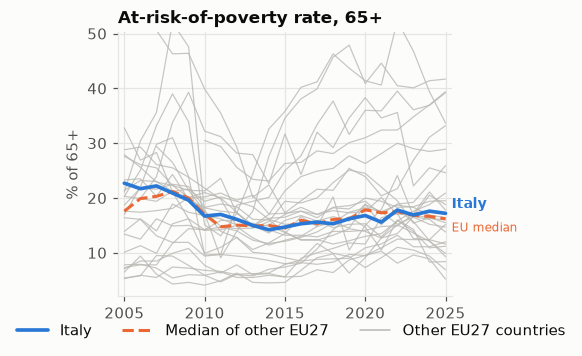

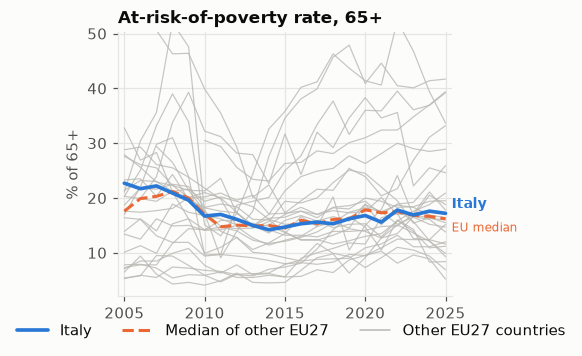

In [5]:
# Old-age poverty (at-risk-of-poverty rate, 65+, 60% of median)
small_multiples(panel, [("arop_65plus", "At-risk-of-poverty rate, 65+", "% of 65+")], ncols=1, name="04_arop65")

In [6]:
# Figures quoted in the takeaways: Italy, median of the other members, rank (1 = highest) among the members with a value
def quoted(ind, years, countries=()):
    w = wide(panel, ind, EU27_ISO3)
    for y in years:
        r = w.loc[y].dropna()
        print(f"{ind} {y}: Italy {r[ITALY]:.2f} | median of the others {r.drop(ITALY).median():.2f} | rank {int(r.rank(ascending=False)[ITALY])}/{len(r)}" + "".join(f" | {c} {r[c]:.2f}" for c in countries))  # two decimals: a takeaway rounded to one is then checked without ties
quoted("old_age_dependency", [2024]); quoted("median_age", [2024]); quoted("fertility_rate", [2024]); quoted("pension_spend_pct_gdp", [2024])
quoted("employment_rate_55_64", [2005, 2024]); quoted("oecd_exit_age_male", [2005, 2024]); quoted("arop_65plus", [2024])

old_age_dependency 2024: Italy 38.40 | median of the others 32.05 | rank 1/27
median_age 2024: Italy 48.70 | median of the others 43.50 | rank 1/27
fertility_rate 2024: Italy 1.18 | median of the others 1.38 | rank 22/27
pension_spend_pct_gdp 2024: Italy 13.90 | median of the others 9.60 | rank 3/27
employment_rate_55_64 2005: Italy 31.40 | median of the others 42.55 | rank 23/27
employment_rate_55_64 2024: Italy 59.00 | median of the others 67.85 | rank 19/27
oecd_exit_age_male 2005: Italy 59.90 | median of the others 60.35 | rank 15/27
oecd_exit_age_male 2024: Italy 64.00 | median of the others 63.60 | rank 11/27
arop_65plus 2024: Italy 17.60 | median of the others 16.65 | rank 13/27


## Takeaways
- **Italy is the oldest EU27 country:** old-age dependency 38.4 (1st of 27), median age 48.7 (1st), fertility 1.2 (22nd).
- **Spending is above what ageing alone predicts.** Public old-age spending was 13.7% of GDP in 2022-24, 3 pp above the 10.8% implied by the other members' relationship with the dependency ratio (3rd highest in 2024). The association with older-worker employment is negative: Italy combines high spending with low 55-64 employment (59.0% vs 67.8% median in 2024).
- **But Italy has moved a lot:** 55-64 employment rose from 31.4% (2005) to 59.0%, and the effective exit age for men from 59.9 to 64.0 (EU median 63.6).
- **Design in 2024 (OECD):** net replacement rate for an average earner 79% (8th of 30; median 72%), gross 70.6% (8th; median 54%); normal retirement age 64.8 now but 70 for future entrants (rank 4-5 of 30). The retirement-age path is the main reform lever already legislated.
- **Old-age poverty is not unusual:** at-risk-of-poverty among 65+ was 17.6% against a 16.6% median in 2024 (gap about 0 sd). The pension system protects the old comparatively well; the cost falls on public finances and on younger cohorts (see notebook 05).